/tmp/ipykernel_1229/3795889596.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Segment', data=rfm, palette='viridis', order=rfm['Segment'].value_counts().index)


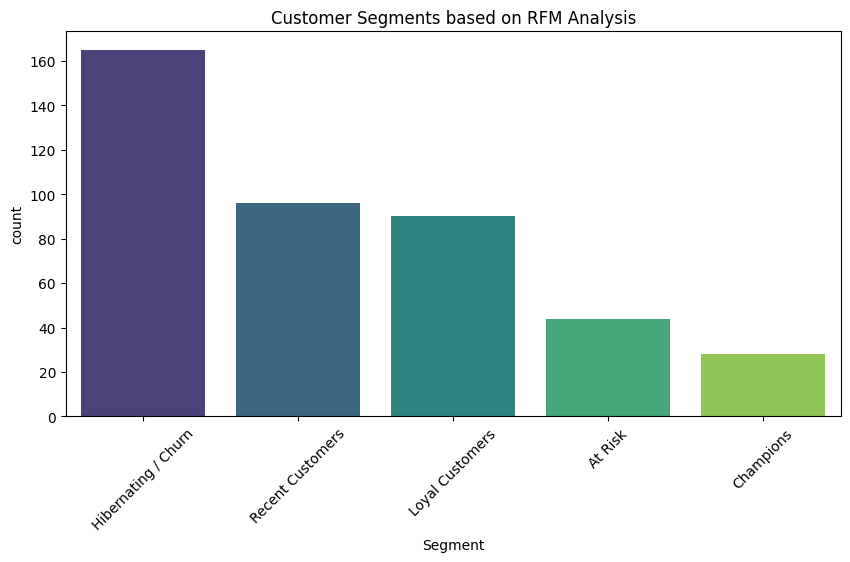

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta

# 1. Load Dataset (Yahan aap original Kaggle dataset load kar sakte hain)
# df = pd.read_csv("your_kaggle_dataset.csv")

# NOTE: Since the provided CSV was empty, generating synthetic data matching your columns for demonstration
np.random.seed(42)
n_rows = 1000
df = pd.DataFrame({
    'Customer ID': np.random.randint(1000, 1500, n_rows),
    'Purchase Date': pd.to_datetime('2023-01-01') + pd.to_timedelta(np.random.randint(0, 365, n_rows), unit='D'),
    'Product Category': np.random.choice(['Electronics', 'Clothing', 'Home', 'Beauty', 'Sports'], n_rows),
    'Product Price': np.round(np.random.uniform(10, 500, n_rows), 2),
    'Quantity': np.random.randint(1, 6, n_rows),
    'Payment Method': np.random.choice(['Credit Card', 'PayPal', 'Debit Card', 'UPI'], n_rows),
    'Returns': np.random.choice([0, 1], n_rows, p=[0.9, 0.1])
})
df['Total Purchase Amount'] = df['Product Price'] * df['Quantity']

# 2. Data Cleaning & Feature Engineering (RFM Analysis)
# Calculating Recency (R), Frequency (F), and Monetary Value (M)
snapshot_date = df['Purchase Date'].max() + timedelta(days=1)
rfm = df.groupby('Customer ID').agg({
    'Purchase Date': lambda x: (snapshot_date - x.max()).days,
    'Customer ID': 'count',
    'Total Purchase Amount': 'sum'
}).rename(columns={'Purchase Date': 'Recency', 'Customer ID': 'Frequency', 'Total Purchase Amount': 'MonetaryValue'})

# 3. Customer Segmentation using Quantiles
quantiles = rfm.quantile(q=[0.25, 0.5, 0.75])

def r_score(x, p, d):
    if x <= d[p][0.25]: return 4
    elif x <= d[p][0.50]: return 3
    elif x <= d[p][0.75]: return 2
    else: return 1

def fm_score(x, p, d):
    if x <= d[p][0.25]: return 1
    elif x <= d[p][0.50]: return 2
    elif x <= d[p][0.75]: return 3
    else: return 4

rfm['R'] = rfm['Recency'].apply(r_score, args=('Recency', quantiles,))
rfm['F'] = rfm['Frequency'].apply(fm_score, args=('Frequency', quantiles,))
rfm['M'] = rfm['MonetaryValue'].apply(fm_score, args=('MonetaryValue', quantiles,))
rfm['RFM_Score'] = rfm['R'].map(str) + rfm['F'].map(str) + rfm['M'].map(str)

# Define Segment Logic
def segment_customer(df):
    if df['RFM_Score'] == '444': return 'Champions'
    elif df['R'] >= 3 and df['F'] >= 3: return 'Loyal Customers'
    elif df['R'] >= 3 and df['F'] <= 2: return 'Recent Customers'
    elif df['R'] <= 2 and df['F'] >= 3: return 'At Risk'
    elif df['R'] <= 2 and df['F'] <= 2: return 'Hibernating / Churn'
    else: return 'Others'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# 4. Visualizations
plt.figure(figsize=(10, 5))
sns.countplot(x= sns.countplot(x='Segment', data=rfm, hue='Segment', palette='viridis', order=rfm['Segment'].value_counts().index, legend=False)
plt.title('Customer Segments based on RFM Analysis')
plt.xticks(rotation=45)
plt.show()